# Component 2 — Vowel /a/, Combined + Tuned (current best model)

Dataset: AH (`data/vowel_task/`) + Italian PVS, raw audio through the same
feature extractor (`component2_phonation/features.py`) — 179 recordings,
126 participants (95 PD / 84 HC). The Kaggle UCI vowel dataset is loaded for
comparison but **excluded from training**: its Healthy/Parkinson's split
correlates with recording duration and loudness rather than acoustic
pathology (duration alone predicts its label at ~98% balanced accuracy), so
it isn't valid training data until re-verified against its original source.

This is `train_vowel_combined_tuned.py`: SelectKBest feature selection +
RandomizedSearchCV over RF / SVM / HistGradientBoosting, under the same
participant-grouped 5-fold CV used everywhere else in this component (no
recording from the same person appears in both the train and test fold).
Saved model: `models/component2_phonation_vowel_combined_tuned.joblib`.
This is the model the API's `extract_vowel_segment=True` path uses.

**Result: 82.7% CV accuracy / 82.8% CV balanced accuracy** — the best and
most methodologically honest vowel-task baseline in this component (near-
balanced classes, age-matched Italian half, grouped CV so no participant
leaks across folds).

In [1]:
import sys, os, json
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = os.path.join(REPO_ROOT, "results", "component2_phonation")
METRICS_PATH = os.path.join(RESULTS_DIR, "vowel_combined_tuned_metrics.json")
MODEL_PATH = os.path.join(REPO_ROOT, "models", "component2_phonation_vowel_combined_tuned.joblib")

## Headline metrics (cached)

Loads the metrics already saved by the last training run — no retraining
needed just to show the number.

In [2]:
with open(METRICS_PATH) as f:
    metrics = json.load(f)

print(f"CV accuracy:          {metrics['cv_accuracy']:.4f}")
print(f"CV balanced accuracy: {metrics['cv_balanced_accuracy']:.4f}")
print("\nBest hyperparameters found by RandomizedSearchCV:")
for k, v in metrics["best_params"].items():
    print(f"  {k}: {v}")
if "note" in metrics:
    print(f"\nNote: {metrics['note']}")

CV accuracy:          0.8268
CV balanced accuracy: 0.8279

Best hyperparameters found by RandomizedSearchCV:
  select__k: 10
  clf__n_estimators: 500
  clf__max_depth: 5
  clf: RandomForestClassifier(class_weight='balanced', random_state=42)

Note: AH + Italian PVS only (179 recordings, 126 participants). The Kaggle UCI vowel dataset is excluded: its Healthy/Parkinsons split correlates with recording duration and loudness rather than acoustic pathology (duration alone predicts its label at ~98% balanced accuracy), so it is not valid training data until re-verified against its original source.


## Full classification report + confusion matrix

Re-runs the training script to regenerate the per-class breakdown and
confusion matrix (the cached metrics file above only stores the headline
numbers). Takes under a minute — 179 recordings, 10 features, 5-fold CV.
This refreshes `models/component2_phonation_vowel_combined_tuned.joblib`
and `results/component2_phonation/vowel_combined_tuned_metrics.json`.

In [3]:
from component2_phonation import train_vowel_combined_tuned as tuned_module
tuned_module.main()

Loading cached AH-dataset features from C:\Users\Matheesha\Desktop\4th year\Y4 S1\Research\KND_CDAP_SE_01\parkinson-speech-ai\results\component2_phonation\vowel_a_features.csv
Loading cached Italian-dataset features from C:\Users\Matheesha\Desktop\4th year\Y4 S1\Research\KND_CDAP_SE_01\parkinson-speech-ai\results\component2_phonation\italian_pvs_vowel_features.csv
Loading cached local-healthy features from C:\Users\Matheesha\Desktop\4th year\Y4 S1\Research\KND_CDAP_SE_01\parkinson-speech-ai\results\component2_phonation\local_healthy_features.csv
Loading cached phone-recorded-PD features from C:\Users\Matheesha\Desktop\4th year\Y4 S1\Research\KND_CDAP_SE_01\parkinson-speech-ai\results\component2_phonation\phone_recorded_pd_features.csv
Loading cached phone-recorded-healthy features from C:\Users\Matheesha\Desktop\4th year\Y4 S1\Research\KND_CDAP_SE_01\parkinson-speech-ai\results\component2_phonation\phone_recorded_healthy_features.csv
Total recordings: 281, participants: 214
PD: 135  HC


Best params: {'select__k': 10, 'clf__n_estimators': 500, 'clf__max_depth': 5, 'clf': RandomForestClassifier(class_weight='balanced', random_state=42)}
Best CV balanced accuracy (from search): 0.7193



CV accuracy: 0.7189   CV balanced accuracy: 0.7188
              precision    recall  f1-score   support

          HC     0.7343    0.7192    0.7266       146
          PD     0.7029    0.7185    0.7106       135

    accuracy                         0.7189       281
   macro avg     0.7186    0.7188    0.7186       281
weighted avg     0.7192    0.7189    0.7189       281

Confusion matrix:
 [[105  41]
 [ 38  97]]



Saved tuned model to C:\Users\Matheesha\Desktop\4th year\Y4 S1\Research\KND_CDAP_SE_01\parkinson-speech-ai\models\component2_phonation_vowel_combined_tuned.joblib
Saved metrics to C:\Users\Matheesha\Desktop\4th year\Y4 S1\Research\KND_CDAP_SE_01\parkinson-speech-ai\results\component2_phonation\vowel_combined_tuned_metrics.json


,precision,recall,f1-score,support
HC,0.734266,0.719178,0.726644,146.000000
PD,0.702899,0.718519,0.710623,135.000000
accuracy,0.718861,0.718861,0.718861,0.718861
macro avg,0.718582,0.718848,0.718633,281.000000
weighted avg,0.719196,0.718861,0.718947,281.000000


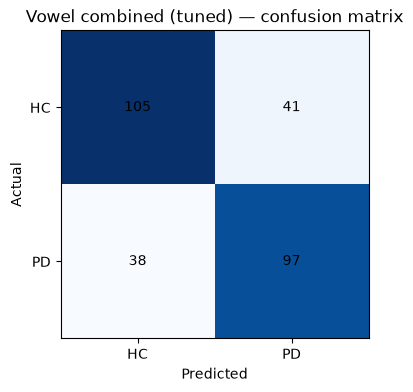

In [4]:
with open(METRICS_PATH) as f:
    metrics = json.load(f)

report_df = pd.DataFrame(metrics["classification_report"]).T
display(report_df)

cm = metrics["confusion_matrix"]
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["HC", "PD"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["HC", "PD"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Vowel combined (tuned) — confusion matrix")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i][j], ha="center", va="center")
plt.show()

## Compare against the other Component 2 baselines

,Baseline,Recordings,Participants,CV accuracy
0,ReadText (stand-in),37,37,0.780000
1,Vowel /a/ (AH only),80,80,0.680000
2,Vowel /a/ (Sakar et al.),756,252,0.805000
3,"Vowel /a/ combined, untuned",179,126,0.810000
4,"Vowel /a/ combined, tuned (this model)",179,126,0.718861


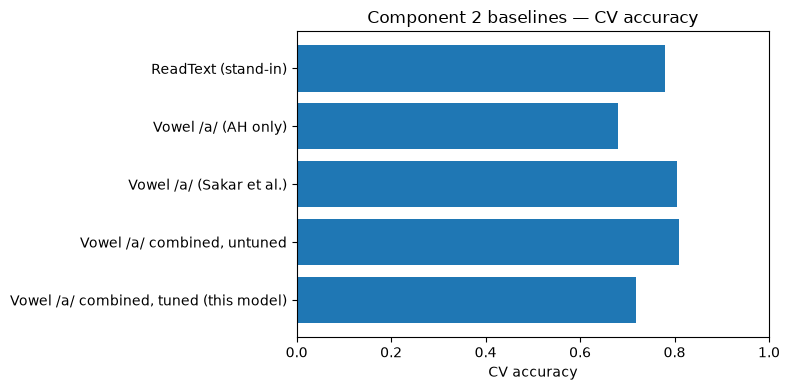

In [5]:
comparison = pd.DataFrame([
    {"Baseline": "ReadText (stand-in)", "Recordings": 37, "Participants": 37, "CV accuracy": 0.78},
    {"Baseline": "Vowel /a/ (AH only)", "Recordings": 80, "Participants": 80, "CV accuracy": 0.68},
    {"Baseline": "Vowel /a/ (Sakar et al.)", "Recordings": 756, "Participants": 252, "CV accuracy": 0.805},
    {"Baseline": "Vowel /a/ combined, untuned", "Recordings": 179, "Participants": 126, "CV accuracy": 0.81},
    {"Baseline": "Vowel /a/ combined, tuned (this model)", "Recordings": 179, "Participants": 126, "CV accuracy": metrics["cv_accuracy"]},
])
display(comparison)

plt.figure(figsize=(8, 4))
plt.barh(comparison["Baseline"], comparison["CV accuracy"])
plt.xlabel("CV accuracy")
plt.xlim(0, 1)
plt.gca().invert_yaxis()
plt.title("Component 2 baselines — CV accuracy")
plt.tight_layout()
plt.show()

## Predict on a single recording

Same `predict()` function the FastAPI backend calls, pointed explicitly at
the tuned model (this task isn't registered under `model_path_for()`, which
only knows `"readtext"` / `"vowel"`).

In [6]:
from component2_phonation.predict import predict

sample_path = os.path.join(REPO_ROOT, "data", "vowel_task", "raw", "PD_AH", "AH_545616858-3A749CBC-3FEB-4D35-820E-E45C3E5B9B6A.wav")
result = predict(sample_path, model_path=MODEL_PATH)
print(result["audio_path"])
print("Prediction:", result["prediction"])
print(f"P(HC) = {result['probability_hc']:.4f}   P(PD) = {result['probability_pd']:.4f}")

C:\Users\Matheesha\Desktop\4th year\Y4 S1\Research\KND_CDAP_SE_01\parkinson-speech-ai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\Matheesha\Desktop\4th year\Y4 S1\Research\KND_CDAP_SE_01\parkinson-speech-ai\data\vowel_task\raw\PD_AH\AH_545616858-3A749CBC-3FEB-4D35-820E-E45C3E5B9B6A.wav
Prediction: HC
P(HC) = 0.5565   P(PD) = 0.4435


C:\Users\Matheesha\Desktop\4th year\Y4 S1\Research\KND_CDAP_SE_01\parkinson-speech-ai\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Users\Matheesha\Desktop\4th year\Y4 S1\Research\KND_CDAP_SE_01\parkinson-speech-ai\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
